# 03 — Baseline Models
## Logistic Regression (Supervised) vs Isolation Forest (Unsupervised)

**เป้าหมาย:** สร้างโมเดลพื้นฐาน (baseline) เป็นเกณฑ์ให้ LSTM / Transformer ต้องทำได้ดีกว่า

**Analogy:** baseline เหมือน detection rule แบบง่ายๆ ที่ SOC มีอยู่แล้ว ถ้าโมเดล Deep Learning ที่ซับซ้อนกว่าทำได้ไม่ดีกว่า rule ง่ายๆ ก็ไม่คุ้มที่จะใช้

| โมเดล | ประเภท | ใช้ Label ตอนเทรน? |
|---|---|---|
| Logistic Regression | Supervised | ✅ ใช้ |
| Isolation Forest | Unsupervised | ❌ ไม่ใช้ (หาตัวที่ "แปลกแยก" เอง) |

> 💡 Isolation Forest มักได้ผลต่ำกว่า Logistic Regression เพราะไม่ได้ดูเฉลยเลย ซึ่งเป็นเรื่องปกติของ baseline แบบ unsupervised

## Step 1: โหลดข้อมูลที่แบ่งไว้จาก notebook 02

In [1]:
import json
import os
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, average_precision_score)

DATA_DIR = '../data/processed/HDFS'
FIG_DIR = '../results/figures'
METRIC_DIR = '../results/metrics'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(METRIC_DIR, exist_ok=True)

train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
val_df = pd.read_csv(f'{DATA_DIR}/val.csv')
test_df = pd.read_csv(f'{DATA_DIR}/test.csv')

print('=' * 60)
for name, d in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f'{name:5s} Set: {len(d):>8,} แถว | Anomaly: {d["Label"].sum():>6,} ({d["Label"].mean() * 100:.2f}%)')

print('\n==== ตัวอย่าง 5 แถวแรก ====')
print(train_df.head())

Train Set:  402,542 แถว | Anomaly: 11,787 (2.93%)
Val   Set:   86,259 แถว | Anomaly:  2,525 (2.93%)
Test  Set:   86,260 แถว | Anomaly:  2,526 (2.93%)

==== ตัวอย่าง 5 แถวแรก ====
                    BlockId  \
0  blk_-2009788189177464759   
1  blk_-3903179602248028496   
2  blk_-8586537078681491164   
3   blk_7650600406872014535   
4  blk_-3252441741952247335   

                                            Sequence  Label  
0  E2 E1 E1 E1 E5 E5 E5 E3 E4 E3 E4 E3 E4 E32 E32...      0  
1  E2 E1 E1 E1 E3 E4 E5 E3 E4 E3 E4 E5 E5 E10 E32...      0  
2  E2 E1 E1 E1 E5 E5 E5 E3 E4 E3 E4 E3 E4 E10 E10...      0  
3             E1 E1 E1 E2 E3 E4 E3 E4 E3 E4 E5 E5 E5      0  
4  E1 E1 E2 E1 E3 E4 E3 E4 E5 E5 E3 E4 E5 E32 E32...      0  


## Step 2: แปลง Sequence → Event Count Vector

### หลักการ:
Logistic Regression และ Isolation Forest รับ input เป็นตารางที่ทุกแถวมีจำนวน column เท่ากัน แต่ session แต่ละอันยาวไม่เท่ากัน
→ เราจึงนับว่าแต่ละ session มี event แต่ละแบบกี่ครั้ง (เหมือน bag-of-words)

ตัวอย่าง: `E5 E5 E22 E11` → `{E5: 2, E22: 1, E11: 1, อื่นๆ: 0}`

⚠️ วิธีนี้ **ไม่สนลำดับ** ของ event ซึ่งเป็นข้อจำกัดที่ LSTM / Transformer จะเข้ามาแก้

In [2]:
# token_pattern=r'\b\w+\b' ให้มอง E1, E22 เป็น 1 token
vectorizer = CountVectorizer(token_pattern=r'\b\w+\b')

# fit_transform เฉพาะ train (เรียน vocab), val/test ใช้ transform อย่างเดียว ไม่ให้ข้อมูลรั่ว
X_train = vectorizer.fit_transform(train_df['Sequence'])
X_val = vectorizer.transform(val_df['Sequence'])
X_test = vectorizer.transform(test_df['Sequence'])

y_train = train_df['Label'].values
y_val = val_df['Label'].values
y_test = test_df['Label'].values

print('=== ขนาด Feature Matrix ===')
print(f'X_train: {X_train.shape} → (Session: {X_train.shape[0]:,}, Event Type: {X_train.shape[1]})')
print(f'X_val:   {X_val.shape} → (Session: {X_val.shape[0]:,}, Event Type: {X_val.shape[1]})')
print(f'X_test:  {X_test.shape} → (Session: {X_test.shape[0]:,}, Event Type: {X_test.shape[1]})')

=== ขนาด Feature Matrix ===
X_train: (402542, 45) → (Session: 402,542, Event Type: 45)
X_val:   (86259, 45) → (Session: 86,259, Event Type: 45)
X_test:  (86260, 45) → (Session: 86,260, Event Type: 45)


## Step 3: Helper Functions สำหรับวัดผล

### Metric ที่ใช้ (ตามฟอร์มเสนอหัวข้อ):
- **F1-Score (หลัก)** → สมดุลระหว่าง Precision และ Recall
- **Precision** → ที่โมเดลเตือนมา จริงกี่ % (ต่ำ = false alarm เยอะ → alert fatigue)
- **Recall** → anomaly จริงทั้งหมด จับได้กี่ % (ต่ำ = incident หลุดรอด)
- **PR-AUC** → วัดภาพรวมโดยไม่ขึ้นกับ threshold เหมาะกับข้อมูลไม่สมดุล

ไม่ใช้ Accuracy เป็นหลัก เพราะถ้าทายว่า Normal ทุก session ก็ได้ ~97% แล้ว

In [3]:
def evaluate(name: str, y_true: np.ndarray, y_pred: np.ndarray, y_score: np.ndarray) -> dict:
    """พิมพ์ classification report และคืนค่า metric หลักเป็น dict"""
    print(f'=== ผลประเมิน {name} บน Test Set ===')
    print(classification_report(y_true, y_pred, target_names=['Normal (0)', 'Anomaly (1)'], digits=4))
    return {
        'f1_score': round(float(f1_score(y_true, y_pred)), 4),
        'precision': round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        'recall': round(float(recall_score(y_true, y_pred)), 4),
        'pr_auc': round(float(average_precision_score(y_true, y_score)), 4),
    }


def plot_confusion(name: str, y_true: np.ndarray, y_pred: np.ndarray, filename: str) -> None:
    """วาด confusion matrix, เซฟรูป และพิมพ์สรุป TN/FP/FN/TP"""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
                xticklabels=['Pred Normal (0)', 'Pred Anomaly (1)'],
                yticklabels=['Actual Normal (0)', 'Actual Anomaly (1)'])
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('Actual Truth')
    plt.xlabel('Predicted by Model')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{filename}', dpi=150)
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f'True Negative  (ปกติ แล้วทายว่าปกติ):         {tn:,} เคส')
    print(f'False Positive (ปกติ แต่เตือนผิด):            {fp:,} เคส (False Alarm)')
    print(f'False Negative (ผิดปกติ แต่โมเดลมองไม่เห็น):   {fn:,} เคส (หลุดรอด)')
    print(f'True Positive  (ผิดปกติ แล้วจับได้จริง):       {tp:,} เคส')


def save_metrics(model: str, metrics: dict, hyperparameters: dict) -> None:
    """บันทึกผลเป็น JSON ตาม format ใน results/README.md (ใช้ต่อใน 06_comparison)"""
    record = {'model': model, 'dataset': 'HDFS', **metrics,
              'hyperparameters': hyperparameters,
              'timestamp': datetime.now().isoformat(timespec='seconds')}
    with open(f'{METRIC_DIR}/{model}_hdfs.json', 'w', encoding='utf-8') as f:
        json.dump(record, f, indent=4, ensure_ascii=False)
    print(f'บันทึกผลที่ {METRIC_DIR}/{model}_hdfs.json')

## Step 4: Logistic Regression (Supervised)

### หลักการ:
เรียนจากตัวอย่างที่มีเฉลย ว่า event แบบไหนที่มักโผล่ใน session ที่ผิดปกติ

- `class_weight='balanced'` → ให้น้ำหนัก anomaly มากขึ้น เพราะมีแค่ ~2.9%
- `max_iter=1000` → ข้อมูลเยอะ ต้องให้เวลาโมเดล converge มากขึ้น (ค่า default 100 อาจไม่พอ)

In [4]:
lr_params = {'class_weight': 'balanced', 'max_iter': 1000, 'random_state': 42}
lr_model = LogisticRegression(**lr_params)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_score_lr = lr_model.predict_proba(X_test)[:, 1]   # ความน่าจะเป็นที่จะเป็น anomaly (ใช้คิด PR-AUC)

lr_metrics = evaluate('Logistic Regression', y_test, y_pred_lr, y_score_lr)

=== ผลประเมิน Logistic Regression บน Test Set ===
              precision    recall  f1-score   support

  Normal (0)     1.0000    0.9988    0.9994     83734
 Anomaly (1)     0.9612    1.0000    0.9802      2526

    accuracy                         0.9988     86260
   macro avg     0.9806    0.9994    0.9898     86260
weighted avg     0.9989    0.9988    0.9988     86260



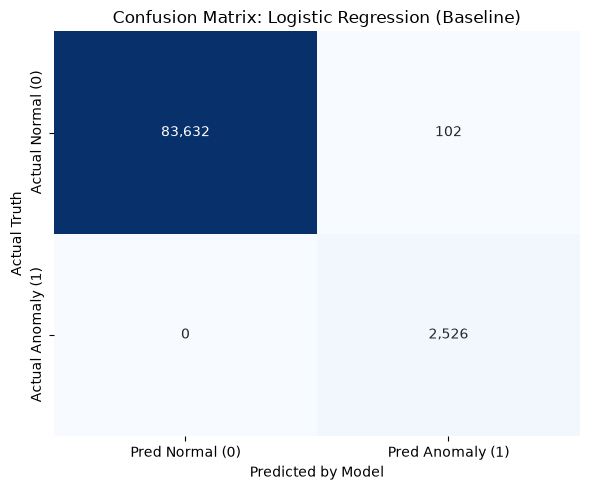

True Negative  (ปกติ แล้วทายว่าปกติ):         83,632 เคส
False Positive (ปกติ แต่เตือนผิด):            102 เคส (False Alarm)
False Negative (ผิดปกติ แต่โมเดลมองไม่เห็น):   0 เคส (หลุดรอด)
True Positive  (ผิดปกติ แล้วจับได้จริง):       2,526 เคส
บันทึกผลที่ ../results/metrics/logistic_regression_hdfs.json


In [5]:
plot_confusion('Logistic Regression (Baseline)', y_test, y_pred_lr, '05_confusion_matrix_lr.png')
save_metrics('logistic_regression', lr_metrics, lr_params)

## Step 5: Isolation Forest (Unsupervised)

### หลักการ:
สุ่มตัดแบ่งข้อมูลไปเรื่อยๆ ตัวที่ "แปลกแยก" จะถูกแยกออกมาได้เร็ว (ใช้จำนวนครั้งตัดน้อย) → ถือว่าผิดปกติ

**Analogy:** เหมือนหาคนแปลกหน้าในออฟฟิศ ไม่ต้องรู้ว่าคนร้ายหน้าตาเป็นยังไง แค่ดูว่าใครไม่เหมือนคนอื่น

- `contamination` → บอกโมเดลว่าน่าจะมีตัวผิดปกติประมาณกี่ % (คำนวณจาก train จริง ไม่ใส่เลขตายตัว)
- Isolation Forest คืนค่า `1 = ปกติ`, `-1 = ผิดปกติ` → ต้องแปลงให้ตรงกับ label ของเรา

In [6]:
contamination = float(y_train.mean())
iso_params = {'n_estimators': 100, 'contamination': round(contamination, 4), 'random_state': 42}
iso_model = IsolationForest(**iso_params, n_jobs=-1)
iso_model.fit(X_train)   # ไม่ส่ง y_train เพราะเป็น unsupervised

raw_pred = iso_model.predict(X_test)
y_pred_iso = (raw_pred == -1).astype(int)      # -1 (ผิดปกติ) → 1, 1 (ปกติ) → 0
y_score_iso = -iso_model.score_samples(X_test)   # ยิ่งมาก = ยิ่งแปลก (ใช้คิด PR-AUC)

print(f'contamination ที่ใช้: {contamination:.4f}\n')
iso_metrics = evaluate('Isolation Forest', y_test, y_pred_iso, y_score_iso)

contamination ที่ใช้: 0.0293

=== ผลประเมิน Isolation Forest บน Test Set ===
              precision    recall  f1-score   support

  Normal (0)     0.9887    0.9897    0.9892     83734
 Anomaly (1)     0.6474    0.6267    0.6369      2526

    accuracy                         0.9791     86260
   macro avg     0.8181    0.8082    0.8131     86260
weighted avg     0.9788    0.9791    0.9789     86260



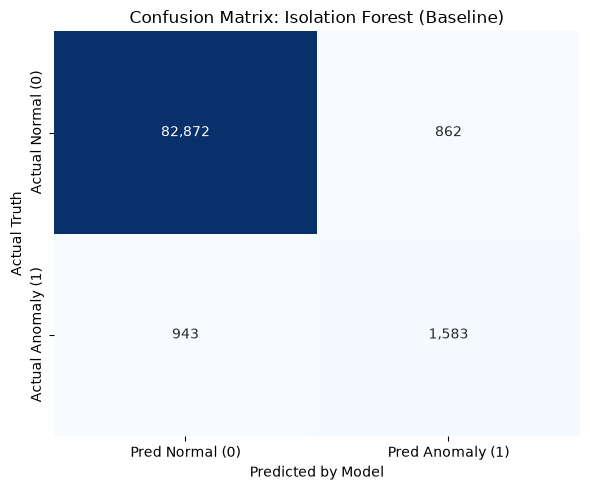

True Negative  (ปกติ แล้วทายว่าปกติ):         82,872 เคส
False Positive (ปกติ แต่เตือนผิด):            862 เคส (False Alarm)
False Negative (ผิดปกติ แต่โมเดลมองไม่เห็น):   943 เคส (หลุดรอด)
True Positive  (ผิดปกติ แล้วจับได้จริง):       1,583 เคส
บันทึกผลที่ ../results/metrics/isolation_forest_hdfs.json


In [7]:
plot_confusion('Isolation Forest (Baseline)', y_test, y_pred_iso, '06_confusion_matrix_iforest.png')
save_metrics('isolation_forest', iso_metrics, iso_params)

## Step 6: เปรียบเทียบ Baseline

In [8]:
comparison = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Type': 'Supervised', **lr_metrics},
    {'Model': 'Isolation Forest', 'Type': 'Unsupervised', **iso_metrics},
]).set_index('Model')

print('=== Baseline Comparison (Test Set, Anomaly class) ===')
comparison

=== Baseline Comparison (Test Set, Anomaly class) ===


,Type,f1_score,precision,recall,pr_auc
Model,,,,,
Logistic Regression,Supervised,0.9802,0.9612,1.0000,0.9753
Isolation Forest,Unsupervised,0.6369,0.6474,0.6267,0.7336


## 📝 สรุป

- **Logistic Regression** ใช้เฉลยตอนเทรน จึงควรได้ผลสูงกว่า
- **Isolation Forest** ไม่ใช้เฉลย ผลจะต่ำกว่าเป็นเรื่องปกติ
- ทั้งสองโมเดลใช้ event count vector ซึ่ง **ไม่สนลำดับ** ของ event

**สิ่งที่ LSTM / Transformer ต้องทำให้ได้:** F1 สูงกว่า baseline โดยใช้ข้อมูลลำดับเหตุการณ์

**ต่อไป:** `04_lstm_deeplog.ipynb` (DeepLog เทรนด้วย session ปกติเท่านั้น → กรอง `Label == 0` ออกจาก train ก่อน)